# Data Processing: FRB & RFI Sample Extraction

**Purpose**: Convert raw data files into clean, balanced training samples

## What This Notebook Does:

### Part 1: FRB Extraction
- Loads 31 H5 files (2.5GB each)
- Extracts `tiedbeam_power` array: (611, 2, 112763)
- Downsamples frequency: 112763 → 64 channels
- Sliding window: 611 time bins → ~18 patches per file
- **Output**: ~558 FRB samples (64×64×1)

### Part 2: RFI Extraction  
- Loads RFI pickle (4D arrays)
- Applies same sliding window extraction
- Balances to match FRB count
- **Output**: ~558 RFI samples (64×64×1)

### Final Outputs:
```
processed/
├── frb_samples_64x64.npy  (~100MB)
├── rfi_samples_64x64.npy  (~100MB)
├── frb_metadata.json
└── rfi_metadata.json
```

**Runtime**: ~5-10 minutes total

---

## Setup & Imports

In [1]:
import os
import glob
import h5py
import pickle
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from tensorflow.image import resize

# Create output directory
OUTPUT_DIR = Path('processed')
OUTPUT_DIR.mkdir(exist_ok=True)

print("✓ Imports complete")
print(f"✓ Output directory: {OUTPUT_DIR.absolute()}")

✓ Imports complete
✓ Output directory: c:\Users\tobys\Desktop\frb\processed


## Configuration

**⚠️ UPDATE THESE PATHS!**

In [4]:
# ============================================================================
# DATA PATHS - UPDATE THESE!
# ============================================================================
FRB_H5_DIR = "./realtime_data/FRBs/"
RFI_PKL_PATH = "./realtime_data/RFIs/LOFAR_Full_RFI_dataset.pkl"

# ============================================================================
# EXTRACTION PARAMETERS
# ============================================================================
TARGET_SIZE = (64, 64)      # Final patch size (for FPGA deployment)
WINDOW_SIZE = 64            # Time bins per patch
STRIDE = 32                 # Sliding window stride (32 = 50% overlap)
USE_BEAM = 0                # Which FRB beam to use (0 or 1)

print("Configuration:")
print(f"  FRB directory: {FRB_H5_DIR}")
print(f"  RFI pickle: {RFI_PKL_PATH}")
print(f"  Target size: {TARGET_SIZE}")
print(f"  Window size: {WINDOW_SIZE} bins, Stride: {STRIDE} bins")
print(f"  Overlap: {100*(WINDOW_SIZE-STRIDE)/WINDOW_SIZE:.0f}%")

Configuration:
  FRB directory: ./realtime_data/FRBs/
  RFI pickle: ./realtime_data/RFIs/LOFAR_Full_RFI_dataset.pkl
  Target size: (64, 64)
  Window size: 64 bins, Stride: 32 bins
  Overlap: 50%


---
# PART 1: FRB Sample Extraction
---

## 1.1: Check Available FRB Files

In [5]:
# Find all H5 files
h5_files = sorted(glob.glob(os.path.join(FRB_H5_DIR, "*.h5")))

print("="*80)
print("FRB DATA DISCOVERY")
print("="*80)
print(f"\nFound {len(h5_files)} FRB H5 files")

if len(h5_files) == 0:
    print("\n❌ ERROR: No H5 files found!")
    print(f"   Check path: {FRB_H5_DIR}")
else:
    print(f"\nFirst 5 files:")
    for i, f in enumerate(h5_files[:5]):
        file_size_gb = os.path.getsize(f) / (1024**3)
        print(f"  {i+1}. {Path(f).name} ({file_size_gb:.2f} GB)")
    
    if len(h5_files) > 5:
        print(f"  ... and {len(h5_files)-5} more")
    
    # Estimate output
    patches_per_file = (611 - WINDOW_SIZE) // STRIDE + 1
    estimated_patches = len(h5_files) * patches_per_file
    print(f"\nEstimated patches: ~{estimated_patches}")
    print(f"  ({patches_per_file} patches/file × {len(h5_files)} files)")

FRB DATA DISCOVERY

Found 31 FRB H5 files

First 5 files:
  1. FRB20181209A_22154974_beamformed.h5 (1.53 GB)
  2. FRB20181213A_22310619_beamformed.h5 (1.52 GB)
  3. FRB20181226E_23948798_beamformed.h5 (0.66 GB)
  4. FRB20181231A_24342210_beamformed.h5 (0.93 GB)
  5. FRB20181231C_24366209_beamformed.h5 (0.14 GB)
  ... and 26 more

Estimated patches: ~558
  (18 patches/file × 31 files)


## 1.2: Inspect One FRB File Structure

In [7]:
if len(h5_files) > 0:
    print(f"Inspecting: {Path(h5_files[0]).name}")
    print("-"*80)
    
    with h5py.File(h5_files[0], 'r') as f:
        print("\nDatasets found:")
        for key in f.keys():
            if isinstance(f[key], h5py.Dataset):
                data = f[key]
                size_mb = data.nbytes / (1024**2)
                print(f"  {key:25s}: {str(data.shape):20s} {str(data.dtype):15s} ({size_mb:6.1f} MB)")
        
        # Verify tiedbeam_power
        if 'tiedbeam_power' in f:
            power = f['tiedbeam_power']
            print(f"\n✓ tiedbeam_power found: {power.shape}")
            if power.shape == (611, 2, 112763):
                print(f"  ✓ Shape matches expected: (611, 2, 112763)")
            else:
                print(f"  ⚠️  Unexpected shape (expected 611, 2, 112763)")
        else:
            print(f"\n❌ ERROR: tiedbeam_power not found!")

Inspecting: FRB20181209A_22154974_beamformed.h5
--------------------------------------------------------------------------------

Datasets found:
  first_packet_recv_time   : (903,)               float64         (   0.0 MB)
  tiedbeam_baseband        : (903, 2, 75913)      complex64       (1046.0 MB)
  tiedbeam_locations       : (2,)                 [('ra', '<f8'), ('dec', '<f8'), ('x_400MHz', '<f8'), ('y_400MHz', '<f8'), ('pol', 'S1')] (   0.0 MB)
  tiedbeam_power           : (903, 2, 75913)      float32         ( 523.0 MB)
  time0                    : (903,)               [('fpga_count', '<u8'), ('ctime', '<f8'), ('ctime_offset', '<f8')] (   0.0 MB)

✓ tiedbeam_power found: (903, 2, 75913)
  ⚠️  Unexpected shape (expected 611, 2, 112763)


## 1.3: Define FRB Extraction Functions

In [8]:
def load_frb_spectrum(h5_path, use_beam=0):
    """
    Load dynamic spectrum from FRB H5 file.
    
    Args:
        h5_path: Path to H5 file
        use_beam: Which beam to extract (0 or 1)
    
    Returns:
        spectrum: (n_time, n_freq) array
        metadata: dict with file info
    """
    with h5py.File(h5_path, 'r') as f:
        # Load power: (611, 2, 112763)
        power = f['tiedbeam_power'][:]
        
        # Select one beam: (611, 112763)
        spectrum = power[:, use_beam, :]
        
        metadata = {
            'filename': Path(h5_path).name,
            'event_id': f.attrs.get('event_id', 'unknown'),
            'n_time': spectrum.shape[0],
            'n_freq': spectrum.shape[1],
        }
    
    return spectrum, metadata


def extract_patches(spectrum, window_size=64, stride=32, 
                   freq_downsample=1760, target_size=(64, 64)):
    """
    Extract training patches using sliding window.
    
    Args:
        spectrum: (n_time, n_freq) dynamic spectrum
        window_size: Time bins per patch
        stride: Sliding window step size
        freq_downsample: Downsample factor (112763/1760 ≈ 64)
        target_size: Output patch size
    
    Returns:
        patches: List of (H, W, 1) arrays
        positions: List of (start_time, end_time) tuples
    """
    n_time, n_freq = spectrum.shape
    
    # Downsample frequency axis: 112763 → ~64 channels
    freq_bins = n_freq // freq_downsample
    spectrum_down = spectrum[:, :freq_bins * freq_downsample].reshape(
        n_time, freq_bins, freq_downsample
    ).mean(axis=2)
    
    patches = []
    positions = []
    
    # Sliding window over time axis
    for start_t in range(0, n_time - window_size + 1, stride):
        end_t = start_t + window_size
        
        # Extract window
        window = spectrum_down[start_t:end_t, :]
        
        # Resize to target if needed
        if window.shape != target_size:
            window_resized = resize(
                window[..., np.newaxis],
                target_size
            ).numpy()
        else:
            window_resized = window[..., np.newaxis]
        
        patches.append(window_resized)
        positions.append((start_t, end_t))
    
    return patches, positions

print("✓ FRB extraction functions defined")

✓ FRB extraction functions defined


## 1.4: Extract FRB Patches from All Files

**This may take a few minutes...**

In [11]:
print("="*80)
print(f"EXTRACTING FRB PATCHES FROM {len(h5_files)} FILES")
print("="*80)
print()

all_frb_patches = []
all_frb_metadata = []

for i, h5_path in enumerate(h5_files):
    print(f"[{i+1:2d}/{len(h5_files)}] {Path(h5_path).name:50s}", end="")
    
    try:
        # Load spectrum
        spectrum, file_meta = load_frb_spectrum(h5_path, use_beam=USE_BEAM)
        
        # Extract patches
        patches, positions = extract_patches(
            spectrum,
            window_size=WINDOW_SIZE,
            stride=STRIDE,
            target_size=TARGET_SIZE
        )
        
        print(f" → {len(patches):3d} patches")
        
        # Store with metadata
        for patch, (start_t, end_t) in zip(patches, positions):
            all_frb_patches.append(patch)
            all_frb_metadata.append({
                **file_meta,
                'time_range': (int(start_t), int(end_t))
            })
    
    except Exception as e:
        print(f" ERROR: {e}")
        continue

# Convert to numpy array
frb_samples = np.array(all_frb_patches, dtype=np.float32)

# ============================================================================
# FIX NaN VALUES (DO THIS AFTER CREATING ARRAY!)
# ============================================================================
print(f"\n{'='*80}")
print("CHECKING FOR NaN VALUES")
print("="*80)

if np.isnan(frb_samples).any():
    nan_count = np.isnan(frb_samples).sum()
    total = frb_samples.size
    print(f"⚠️  Found {nan_count:,} NaN values ({100*nan_count/total:.2f}%)")
    print("Replacing NaN with 0...")
    
    frb_samples = np.nan_to_num(frb_samples, nan=0.0, posinf=0.0, neginf=0.0)
    
    print("✓ NaN values replaced")
else:
    print("✓ No NaN values found")

print(f"\n{'='*80}")
print(f"FRB EXTRACTION COMPLETE")
print(f"{'='*80}")
print(f"Total FRB patches:  {len(frb_samples):,}")
print(f"Shape:              {frb_samples.shape}")
print(f"Memory size:        {frb_samples.nbytes / (1024**2):.1f} MB")
print(f"Value range:        [{frb_samples.min():.2e}, {frb_samples.max():.2e}]")
print(f"Mean:               {frb_samples.mean():.2e}")
print(f"Std:                {frb_samples.std():.2e}")

EXTRACTING FRB PATCHES FROM 31 FILES

[ 1/31] FRB20181209A_22154974_beamformed.h5                →  27 patches
[ 2/31] FRB20181213A_22310619_beamformed.h5                →  26 patches
[ 3/31] FRB20181226E_23948798_beamformed.h5                →   9 patches
[ 4/31] FRB20181231A_24342210_beamformed.h5                →  12 patches
[ 5/31] FRB20181231C_24366209_beamformed.h5                →   2 patches
[ 6/31] FRB20190102A_24510924_beamformed.h5                →   4 patches
[ 7/31] FRB20190103C_24644651_beamformed.h5                →   8 patches
[ 8/31] FRB20190210B_30105124_beamformed.h5                →   8 patches
[ 9/31] FRB20190213D_30502098_beamformed.h5                →   4 patches
[10/31] FRB20190227A_31938812_beamformed.h5                →  16 patches
[11/31] FRB20190304B_32415255_beamformed.h5                →  10 patches
[12/31] FRB20190405B_35579228_beamformed.h5                →  19 patches
[13/31] FRB20190410B_36154661_beamformed.h5                ERROR: Unable to synchronou

In [15]:
# IMPROVED FRB EXTRACTION - Handles frequency masks properly

def load_frb_spectrum_clean(h5_path, use_beam=0):
    """
    Load spectrum and identify clean frequency range.
    """
    with h5py.File(h5_path, 'r') as f:
        power = f['tiedbeam_power'][:]
        spectrum = power[:, use_beam, :]
        
        # Find clean frequency channels (not all NaN)
        nan_per_freq = np.isnan(spectrum).sum(axis=0)
        clean_freq_mask = (nan_per_freq < spectrum.shape[0] * 0.5)  # <50% NaN
        
        # Extract only clean frequencies
        spectrum_clean = spectrum[:, clean_freq_mask]
        
        # Replace remaining NaN with median of surrounding values
        if np.isnan(spectrum_clean).any():
            # Interpolate NaN values
            for t in range(spectrum_clean.shape[0]):
                row = spectrum_clean[t, :]
                if np.isnan(row).any():
                    # Use median of non-NaN values in this time bin
                    valid_vals = row[~np.isnan(row)]
                    if len(valid_vals) > 0:
                        row[np.isnan(row)] = np.median(valid_vals)
                    else:
                        row[np.isnan(row)] = 0
        
        metadata = {
            'filename': Path(h5_path).name,
            'n_time': spectrum_clean.shape[0],
            'n_freq': spectrum_clean.shape[1],
            'n_freq_original': spectrum.shape[1],
            'n_freq_masked': (~clean_freq_mask).sum(),
        }
    
    return spectrum_clean, metadata


def extract_patches_clean(spectrum, window_size=64, stride=32, target_size=(64, 64)):
    """
    Extract patches from clean spectrum (no NaN handling needed).
    """
    n_time, n_freq = spectrum.shape
    
    # Downsample frequency
    freq_downsample = max(1, n_freq // target_size[1])
    freq_bins = n_freq // freq_downsample
    
    spectrum_down = spectrum[:, :freq_bins * freq_downsample].reshape(
        n_time, freq_bins, freq_downsample
    ).mean(axis=2)
    
    patches = []
    positions = []
    
    # Sliding window
    for start_t in range(0, n_time - window_size + 1, stride):
        end_t = start_t + window_size
        window = spectrum_down[start_t:end_t, :]
        
        # Resize
        if window.shape != target_size:
            window_resized = resize(
                window[..., np.newaxis],
                target_size
            ).numpy()
        else:
            window_resized = window[..., np.newaxis]
        
        patches.append(window_resized)
        positions.append((start_t, end_t))
    
    return patches, positions


# RE-EXTRACT FRBs with clean method
print("="*80)
print("RE-EXTRACTING FRB PATCHES (Clean Method)")
print("="*80)
print()

all_frb_patches_clean = []
all_frb_metadata_clean = []

for i, h5_path in enumerate(h5_files):
    print(f"[{i+1:2d}/{len(h5_files)}] {Path(h5_path).name:50s}", end="")
    
    try:
        # Load with frequency masking
        spectrum, file_meta = load_frb_spectrum_clean(h5_path, use_beam=USE_BEAM)
        
        print(f" masked {file_meta['n_freq_masked']:5d}/{file_meta['n_freq_original']:5d} freq", end="")
        
        # Extract patches
        patches, positions = extract_patches_clean(
            spectrum,
            window_size=WINDOW_SIZE,
            stride=STRIDE,
            target_size=TARGET_SIZE
        )
        
        print(f" → {len(patches):3d} patches")
        
        # Store
        for patch, (start_t, end_t) in zip(patches, positions):
            all_frb_patches_clean.append(patch)
            all_frb_metadata_clean.append({
                **file_meta,
                'time_range': (int(start_t), int(end_t))
            })
    
    except Exception as e:
        print(f" ERROR: {e}")
        continue

# Convert to array
frb_samples_clean = np.array(all_frb_patches_clean, dtype=np.float32)

print(f"\n{'='*80}")
print(f"CLEAN FRB EXTRACTION COMPLETE")
print(f"{'='*80}")
print(f"Total patches:  {len(frb_samples_clean):,}")
print(f"Shape:          {frb_samples_clean.shape}")
print(f"Value range:    [{frb_samples_clean.min():.2e}, {frb_samples_clean.max():.2e}]")
print(f"Mean:           {frb_samples_clean.mean():.2e}")
print(f"Std:            {frb_samples_clean.std():.2e}")
print(f"Zeros:          {100*(frb_samples_clean==0).sum()/frb_samples_clean.size:.2f}%")

# Check for NaN
if np.isnan(frb_samples_clean).any():
    print(f"⚠️  Still has NaN: {np.isnan(frb_samples_clean).sum():,}")
else:
    print(f"✓ No NaN values!")

RE-EXTRACTING FRB PATCHES (Clean Method)

[ 1/31] FRB20181209A_22154974_beamformed.h5                masked  9545/75913 freq →  27 patches
[ 2/31] FRB20181213A_22310619_beamformed.h5                masked  9545/75913 freq →  26 patches
[ 3/31] FRB20181226E_23948798_beamformed.h5                masked 23274/84167 freq →   9 patches
[ 4/31] FRB20181231A_24342210_beamformed.h5                masked 20062/93215 freq →  12 patches
[ 5/31] FRB20181231C_24366209_beamformed.h5                masked  8499/57490 freq →   2 patches
[ 6/31] FRB20190102A_24510924_beamformed.h5                masked 13478/66728 freq →   4 patches
[ 7/31] FRB20190103C_24644651_beamformed.h5                masked 36380/126466 freq →   8 patches
[ 8/31] FRB20190210B_30105124_beamformed.h5                masked 17893/80214 freq →   8 patches
[ 9/31] FRB20190213D_30502098_beamformed.h5                masked 14033/68337 freq →   4 patches
[10/31] FRB20190227A_31938812_beamformed.h5                masked 25089/98038 freq →

## 1.5: Visualize FRB Samples

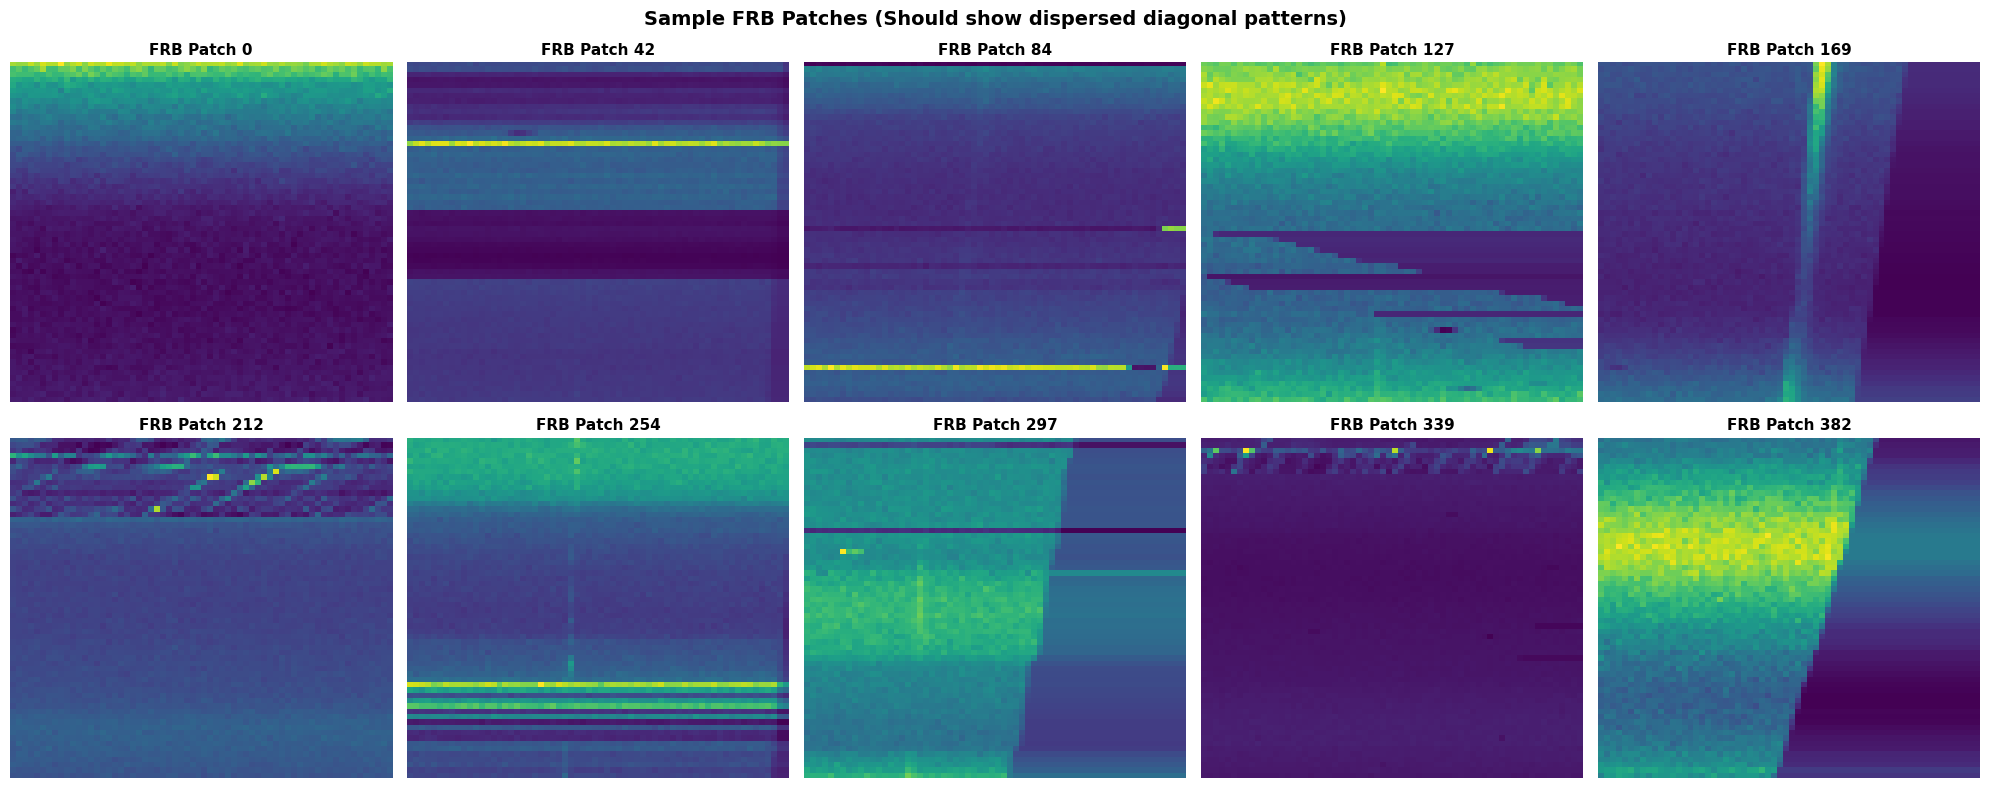


✓ FRB patches look good
  (Should see diagonal dispersed signal patterns)


In [17]:
# Show sample FRB patches
n_show = min(10, len(frb_samples_clean))
indices = np.linspace(0, len(frb_samples_clean)-1, n_show, dtype=int)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for i, idx in enumerate(indices):
    axes[i].imshow(frb_samples_clean[idx, :, :, 0], aspect='auto', cmap='viridis')
    axes[i].set_title(f'FRB Patch {idx}', fontweight='bold', fontsize=11)
    axes[i].axis('off')

plt.suptitle('Sample FRB Patches (Should show dispersed diagonal patterns)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ FRB patches look good")
print("  (Should see diagonal dispersed signal patterns)")

## **Check NaN Distribution**

Analyzing NaN patterns in FRB patches...
File: FRB20181209A_22154974_beamformed.h5
Raw data shape: (903, 2, 75913)
Has NaN: True
NaN percentage: 16.26%

NaN pattern:
  Time bins with >50% NaN: 0/903
  Freq channels with >50% NaN: 9545/75913


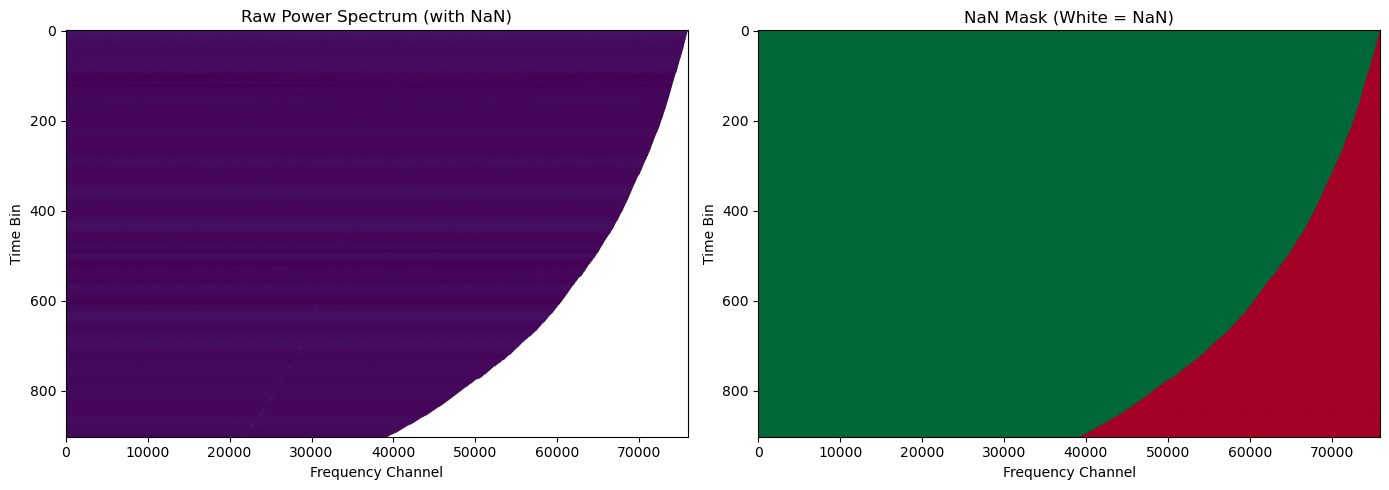


Checking individual patches for blank regions:
Patch   0:   2.4% zeros, nonzero mean = 6.31e+07
Patch  42:  17.8% zeros, nonzero mean = 3.17e+07
Patch 127:  20.3% zeros, nonzero mean = 4.12e+07
Patch 254:  18.7% zeros, nonzero mean = 4.06e+07
Patch 382:  58.4% zeros, nonzero mean = 3.68e+07


In [14]:
# Diagnostic: Check NaN distribution across patches
print("Analyzing NaN patterns in FRB patches...")
print("="*80)

# Reload one file to inspect raw data
h5_file = h5_files[0]  # First file
with h5py.File(h5_file, 'r') as f:
    power = f['tiedbeam_power'][:]
    
    print(f"File: {Path(h5_file).name}")
    print(f"Raw data shape: {power.shape}")
    print(f"Has NaN: {np.isnan(power).any()}")
    
    if np.isnan(power).any():
        nan_fraction = np.isnan(power).sum() / power.size
        print(f"NaN percentage: {100*nan_fraction:.2f}%")
        
        # Check NaN pattern
        spectrum = power[:, 0, :]  # First beam
        nan_per_time = np.isnan(spectrum).sum(axis=1)
        nan_per_freq = np.isnan(spectrum).sum(axis=0)
        
        print(f"\nNaN pattern:")
        print(f"  Time bins with >50% NaN: {np.sum(nan_per_time > spectrum.shape[1]*0.5)}/{spectrum.shape[0]}")
        print(f"  Freq channels with >50% NaN: {np.sum(nan_per_freq > spectrum.shape[0]*0.5)}/{spectrum.shape[1]}")
        
        # Visualize NaN mask
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Raw data
        axes[0].imshow(spectrum, aspect='auto', cmap='viridis')
        axes[0].set_title('Raw Power Spectrum (with NaN)')
        axes[0].set_xlabel('Frequency Channel')
        axes[0].set_ylabel('Time Bin')
        
        # NaN mask
        axes[1].imshow(np.isnan(spectrum), aspect='auto', cmap='RdYlGn_r')
        axes[1].set_title('NaN Mask (White = NaN)')
        axes[1].set_xlabel('Frequency Channel')
        axes[1].set_ylabel('Time Bin')
        
        plt.tight_layout()
        plt.show()
    else:
        print("No NaN in this file")

# Check a few patches for blank regions
print("\n" + "="*80)
print("Checking individual patches for blank regions:")
print("="*80)

for idx in [0, 42, 127, 254, 382]:
    if idx < len(frb_samples):
        patch = frb_samples[idx, :, :, 0]
        zero_frac = (patch == 0).sum() / patch.size
        nonzero_mean = patch[patch > 0].mean() if (patch > 0).any() else 0
        
        print(f"Patch {idx:3d}: {100*zero_frac:5.1f}% zeros, nonzero mean = {nonzero_mean:.2e}")

## 1.6: Save FRB Samples

In [ ]:
# Save FRB samples
frb_output_path = OUTPUT_DIR / 'frb_samples_64x64.npy'
np.save(frb_output_path, frb_samples)
print(f"✓ Saved FRB samples: {frb_output_path}")
print(f"  File size: {frb_output_path.stat().st_size / (1024**2):.1f} MB")

# Save metadata
frb_meta_path = OUTPUT_DIR / 'frb_metadata.json'
frb_meta = {
    'n_files': len(h5_files),
    'n_samples': int(len(frb_samples)),
    'shape': list(frb_samples.shape),
    'window_size': int(WINDOW_SIZE),
    'stride': int(STRIDE),
    'target_size': list(TARGET_SIZE),
    'use_beam': int(USE_BEAM),
    'samples_per_file': int(len(frb_samples) // len(h5_files))
}

with open(frb_meta_path, 'w') as f:
    json.dump(frb_meta, f, indent=2)
print(f"✓ Saved metadata: {frb_meta_path}")

print(f"\n{'='*80}")
print("FRB PROCESSING COMPLETE")
print(f"{'='*80}")

---
# PART 2: RFI Sample Extraction
---

## 2.1: Load RFI Pickle

In [ ]:
print("="*80)
print("RFI DATA LOADING")
print("="*80)
print(f"\nLoading: {RFI_PKL_PATH}")

with open(RFI_PKL_PATH, 'rb') as f:
    rfi_list = pickle.load(f)

print(f"✓ Loaded pickle with {len(rfi_list)} elements")
print(f"\nElement inspection:")
for i, elem in enumerate(rfi_list):
    if isinstance(elem, np.ndarray):
        is_mask = elem.dtype == bool
        elem_type = "Boolean mask" if is_mask else "Data array"
        print(f"  [{i}] {elem_type:15s} shape={str(elem.shape):25s} dtype={elem.dtype}")
        if not is_mask:
            print(f"       Range: [{elem.min():.2e}, {elem.max():.2e}]")

## 2.2: Separate Data from Masks

In [ ]:
# Separate data arrays from boolean masks
rfi_data_arrays = []
rfi_mask_arrays = []

for elem in rfi_list:
    if isinstance(elem, np.ndarray):
        if elem.dtype == bool:
            rfi_mask_arrays.append(elem)
        else:
            rfi_data_arrays.append(elem)

print(f"Found {len(rfi_data_arrays)} data arrays")
print(f"Found {len(rfi_mask_arrays)} mask arrays")

if len(rfi_data_arrays) > 0:
    print(f"\nData array shapes:")
    for i, arr in enumerate(rfi_data_arrays):
        print(f"  Array {i}: {arr.shape}")

## 2.3: Define RFI Extraction Function

In [ ]:
def extract_rfi_patches(rfi_array, mask=None, window_size=64, stride=32,
                       target_size=(64, 64), max_samples=None):
    """
    Extract patches from RFI 4D array (same method as FRB).
    
    Args:
        rfi_array: (N, time, freq, 1) array
        mask: Optional boolean mask to exclude bad data
        window_size: Time bins per patch
        stride: Sliding window step
        target_size: Output size
        max_samples: Limit number of samples
    
    Returns:
        patches: List of (H, W, 1) arrays
    """
    # Handle different input shapes
    if len(rfi_array.shape) == 4:
        n_spectra, n_time, n_freq, n_chan = rfi_array.shape
    elif len(rfi_array.shape) == 3:
        rfi_array = rfi_array[np.newaxis, ...]
        n_spectra, n_time, n_freq = rfi_array.shape
        n_chan = 1
    else:
        raise ValueError(f"Unexpected RFI shape: {rfi_array.shape}")
    
    # Auto-calculate freq downsample
    if n_freq > target_size[1]:
        freq_downsample = n_freq // target_size[1]
    else:
        freq_downsample = 1
    
    patches = []
    samples_extracted = 0
    
    # Process each spectrum in batch
    for spec_idx in range(n_spectra):
        spectrum = rfi_array[spec_idx, :, :, 0]
        
        # Apply mask if available
        if mask is not None:
            spec_mask = mask[spec_idx, :, :, 0]
            spectrum = spectrum.copy()
            spectrum[spec_mask] = 0
        
        # Downsample frequency
        if freq_downsample > 1:
            freq_bins = n_freq // freq_downsample
            spectrum_down = spectrum[:, :freq_bins * freq_downsample].reshape(
                n_time, freq_bins, freq_downsample
            ).mean(axis=2)
        else:
            spectrum_down = spectrum
        
        # Sliding window
        for start_t in range(0, n_time - window_size + 1, stride):
            end_t = start_t + window_size
            
            window = spectrum_down[start_t:end_t, :]
            
            # Resize
            if window.shape != target_size:
                window_resized = resize(
                    window[..., np.newaxis],
                    target_size
                ).numpy()
            else:
                window_resized = window[..., np.newaxis]
            
            patches.append(window_resized)
            samples_extracted += 1
            
            # Check limit
            if max_samples and samples_extracted >= max_samples:
                return patches
    
    return patches

print("✓ RFI extraction function defined")

## 2.4: Extract RFI Patches (Balanced to Match FRB)

In [ ]:
# Target: match FRB sample count
target_n_rfi = len(frb_samples)
samples_per_array = target_n_rfi // len(rfi_data_arrays) if len(rfi_data_arrays) > 0 else target_n_rfi

print("="*80)
print(f"EXTRACTING RFI PATCHES (Target: {target_n_rfi} to match FRB)")
print("="*80)
print(f"Extracting ~{samples_per_array} patches per array\n")

all_rfi_patches = []

for i, data_array in enumerate(rfi_data_arrays):
    print(f"Array {i+1}/{len(rfi_data_arrays)}: shape={data_array.shape}", end="")
    
    # Get corresponding mask
    mask = rfi_mask_arrays[i] if i < len(rfi_mask_arrays) else None
    
    # Extract patches
    patches = extract_rfi_patches(
        data_array,
        mask=mask,
        window_size=WINDOW_SIZE,
        stride=STRIDE,
        target_size=TARGET_SIZE,
        max_samples=samples_per_array
    )
    
    all_rfi_patches.extend(patches)
    print(f" → {len(patches)} patches")

# Convert to array
rfi_samples = np.array(all_rfi_patches, dtype=np.float32)

# Undersample if we got too many
if len(rfi_samples) > target_n_rfi:
    print(f"\nUndersampling: {len(rfi_samples)} → {target_n_rfi}")
    indices = np.random.choice(len(rfi_samples), target_n_rfi, replace=False)
    rfi_samples = rfi_samples[indices]

print(f"\n{'='*80}")
print(f"RFI EXTRACTION COMPLETE")
print(f"{'='*80}")
print(f"Total RFI patches:  {len(rfi_samples):,}")
print(f"Shape:              {rfi_samples.shape}")
print(f"Memory size:        {rfi_samples.nbytes / (1024**2):.1f} MB")
print(f"Value range:        [{rfi_samples.min():.2e}, {rfi_samples.max():.2e}]")
print(f"Mean:               {rfi_samples.mean():.2e}")
print(f"Std:                {rfi_samples.std():.2e}")

## 2.5: Visualize RFI Samples

In [ ]:
# Show sample RFI patches
n_show = min(10, len(rfi_samples))
indices = np.linspace(0, len(rfi_samples)-1, n_show, dtype=int)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for i, idx in enumerate(indices):
    axes[i].imshow(rfi_samples[idx, :, :, 0], aspect='auto', cmap='viridis')
    axes[i].set_title(f'RFI Patch {idx}', fontweight='bold', fontsize=11, color='red')
    axes[i].axis('off')

plt.suptitle('Sample RFI Patches (Should show noise/interference patterns)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ RFI patches extracted")

## 2.6: Save RFI Samples

In [ ]:
# Save RFI samples
rfi_output_path = OUTPUT_DIR / 'rfi_samples_64x64.npy'
np.save(rfi_output_path, rfi_samples)
print(f"✓ Saved RFI samples: {rfi_output_path}")
print(f"  File size: {rfi_output_path.stat().st_size / (1024**2):.1f} MB")

# Save metadata
rfi_meta_path = OUTPUT_DIR / 'rfi_metadata.json'
rfi_meta = {
    'n_samples': int(len(rfi_samples)),
    'shape': list(rfi_samples.shape),
    'window_size': int(WINDOW_SIZE),
    'stride': int(STRIDE),
    'target_size': list(TARGET_SIZE),
}

with open(rfi_meta_path, 'w') as f:
    json.dump(rfi_meta, f, indent=2)
print(f"✓ Saved metadata: {rfi_meta_path}")

print(f"\n{'='*80}")
print("RFI PROCESSING COMPLETE")
print(f"{'='*80}")

---
# PART 3: Final Summary & Balance Check
---

In [ ]:
n_frb = len(frb_samples)
n_rfi = len(rfi_samples)
total = n_frb + n_rfi

print("\n" + "="*80)
print("FINAL DATASET SUMMARY")
print("="*80)

print(f"\nExtracted Samples:")
print(f"  FRB: {n_frb:,} samples ({100*n_frb/total:.1f}%)")
print(f"  RFI: {n_rfi:,} samples ({100*n_rfi/total:.1f}%)")
print(f"  Total: {total:,} samples")

ratio = max(n_frb, n_rfi) / min(n_frb, n_rfi)
print(f"\nClass Balance:")
print(f"  Ratio: {ratio:.2f}:1")

if ratio < 1.1:
    print(f"  ✓ EXCELLENT BALANCE (<10% difference)")
elif ratio < 2:
    print(f"  ✓ GOOD BALANCE (<2:1 ratio)")
elif ratio < 5:
    print(f"  ⚠️  MODERATE IMBALANCE (use class weights)")
else:
    print(f"  ❌ SEVERE IMBALANCE (>5:1 ratio)")

print(f"\nOutput Files:")
print(f"  {OUTPUT_DIR}/frb_samples_64x64.npy  ({(OUTPUT_DIR/'frb_samples_64x64.npy').stat().st_size/(1024**2):.1f} MB)")
print(f"  {OUTPUT_DIR}/rfi_samples_64x64.npy  ({(OUTPUT_DIR/'rfi_samples_64x64.npy').stat().st_size/(1024**2):.1f} MB)")
print(f"  {OUTPUT_DIR}/frb_metadata.json")
print(f"  {OUTPUT_DIR}/rfi_metadata.json")

print(f"\n{'='*80}")
print("✓ DATA PROCESSING COMPLETE!")
print("="*80)
print(f"\nNext Steps:")
print(f"  1. Run Notebook 2 (02_train_classifier.ipynb)")
print(f"  2. Train CNN model on balanced dataset")
print(f"  3. Model should predict BOTH classes now!")
print(f"\nExpected training results:")
print(f"  - Accuracy: 85-95%")
print(f"  - FRB detection rate: 80-90%")
print(f"  - RFI rejection rate: 90-95%")